Total observations: 300


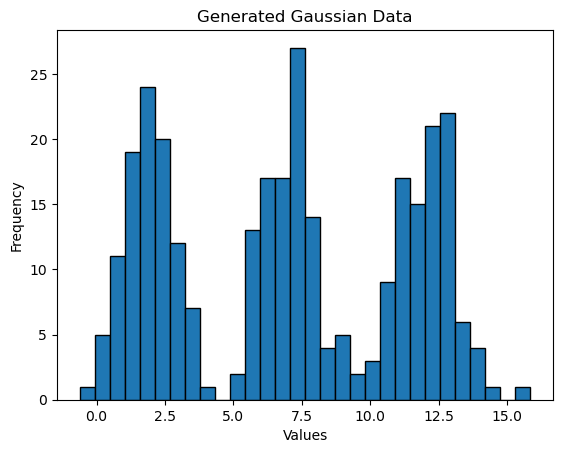

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

# Set seed for reproducibility
np.random.seed(42)

# Generate 3 groups of 100 observations each
group1 = np.random.normal(2, 1, 100)
group2 = np.random.normal(7, 1, 100)
group3 = np.random.normal(12, 1, 100)

# Combine and reshape into a 2D column vector for scikit-learn
data = np.concatenate([group1, group2, group3])
X = data.reshape(-1, 1)

print("Total observations:", len(X))

# Visualize the distribution
plt.hist(X, bins=30, edgecolor="black")
plt.title("Generated Gaussian Data")
plt.xlabel("Values")
plt.ylabel("Frequency")
plt.show()

C:\Users\Administrator\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Administrator\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Administrator\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Administrator\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~

First 20 predicted labels: [2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]


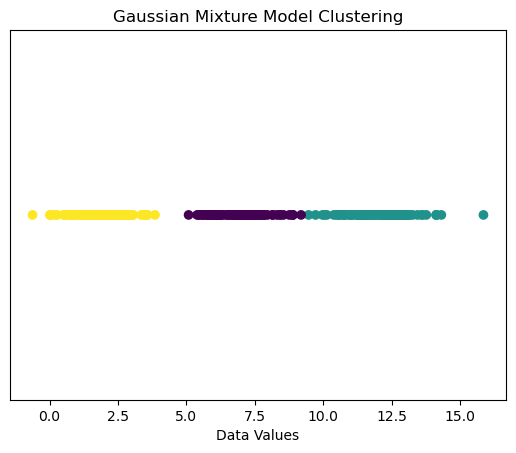

In [2]:
# Create and train the GMM model
gmm = GaussianMixture(n_components=3, random_state=42)
gmm.fit(X)

# Predict group membership
labels = gmm.predict(X)
print("First 20 predicted labels:", labels[:20])

# Display clustering results
plt.scatter(X[:, 0], np.zeros(len(X)), c=labels, cmap="viridis")
plt.title("Gaussian Mixture Model Clustering")
plt.xlabel("Data Values")
plt.yticks([])
plt.show()

In [3]:
print("Estimated Means:\n", gmm.means_)
print("\nEstimated Variances:\n", gmm.covariances_)
print("\nMixing Proportions:\n", gmm.weights_)

Estimated Means:
 [[ 6.98734645]
 [12.04041718]
 [ 1.89614955]]

Estimated Variances:
 [[[0.8221013 ]]

 [[1.19793122]]

 [[0.81819915]]]

Mixing Proportions:
 [0.32957963 0.33717043 0.33324994]


Components: 1 | BIC: 1733.11
Components: 2 | BIC: 1655.28
Components: 3 | BIC: 1526.83
Components: 4 | BIC: 1545.74


C:\Users\Administrator\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Administrator\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Administrator\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Administrator\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known

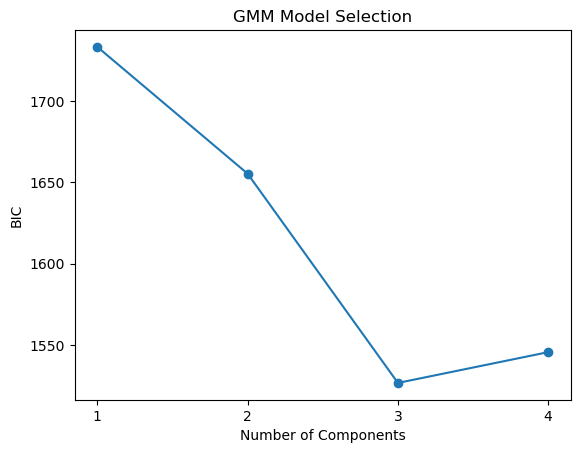

In [4]:
components = [1, 2, 3, 4]
bic_values = []

for k in components:
    model = GaussianMixture(n_components=k, random_state=42)
    model.fit(X)
    bic = model.bic(X)
    bic_values.append(bic)
    print(f"Components: {k} | BIC: {bic:.2f}")

plt.plot(components, bic_values, marker="o")
plt.xlabel("Number of Components")
plt.ylabel("BIC")
plt.title("GMM Model Selection")
plt.xticks(components)
plt.show()

In [1]:
""" Lab 14 Assessment Solutions
1.	EM algorithm: An iterative statistical method used to estimate unknown parameters in models that have missing or hidden (latent) data. 
2.	Gaussian Mixture Model (GMM): A probabilistic model that assumes the observed data is generated from a mixture of two or more normal (Gaussian) distributions. 
3.	E-step vs. M-step: The E-step (Expectation) estimates the probability that each observation belongs to each group, while the M-step (Maximization) updates the parameters (means, variances, weights) of each group using those probabilities. 
4.	Importance of clustering: It automatically uncovers hidden patterns, subgroups, or structures in unlabeled data. 
5.	Purpose of n_components: It specifies the number of Gaussian distributions (clusters/groups) the model should fit to the data. 
6.	Importance of BIC: The Bayesian Information Criterion compares statistical models by balancing goodness-of-fit against model complexity; a lower BIC indicates a preferred model. 
7.	What fit() does: It runs the EM algorithm on the dataset to estimate the optimal parameters (means, covariances, and mixing proportions) of the Gaussian distributions. 
8.	Two practical applications of GMM: Customer segmentation and grouping biological/student measurements (e.g., heights) into distinct subpop

"""

' Lab 14 Assessment Solutions\n1.\tEM algorithm: An iterative statistical method used to estimate unknown parameters in models that have missing or hidden (latent) data. \n2.\tGaussian Mixture Model (GMM): A probabilistic model that assumes the observed data is generated from a mixture of two or more normal (Gaussian) distributions. \n3.\tE-step vs. M-step: The E-step (Expectation) estimates the probability that each observation belongs to each group, while the M-step (Maximization) updates the parameters (means, variances, weights) of each group using those probabilities. \n4.\tImportance of clustering: It automatically uncovers hidden patterns, subgroups, or structures in unlabeled data. \n5.\tPurpose of n_components: It specifies the number of Gaussian distributions (clusters/groups) the model should fit to the data. \n6.\tImportance of BIC: The Bayesian Information Criterion compares statistical models by balancing goodness-of-fit against model complexity; a lower BIC indicates a p